# Clase Práctica 1 – Introducción al Aprendizaje Automático

En esta actividad exploraremos un dataset simple, identificaremos el tipo de aprendizaje adecuado, entrenaremos nuestro primer modelo con scikit‑learn y resolveremos dos desafíos gamificados.

**Autor:** Enzo Fernandez

Ref. Material adaptado de la Clase del  Prof. Dr. Pástor E Pérez *Estigarribia*

## Instalar e importar bibliotecas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [2]:
data = load_iris()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Pregunta 1
El dataset Iris contiene ejemplos etiquetados (clases 0, 1 y 2).  
**¿Este problema corresponde a aprendizaje supervisado o no supervisado? Explica por qué.**

#### Respuesta 1

Es un problema de **aprendizaje supervisado**, concretamente de **clasificación multiclase**.

- Cada ejemplo trae sus atributos de entrada `X` (largo y ancho de sépalo y pétalo) **y** la
  respuesta correcta `y` (la especie: 0 = setosa, 1 = versicolor, 2 = virginica).
- El modelo aprende la función `f(X) → y` a partir de esos pares etiquetados y luego la usamos para
  predecir la especie de flores nuevas. Podemos medir qué tan bien lo hace comparando contra la
  etiqueta real (accuracy).
- Como la salida es una categoría discreta (y no un número continuo), es **clasificación** y no regresión.

Si ignoráramos la columna `target` y solo buscáramos grupos parecidos entre las flores (p. ej. con
*k-means*), el mismo dataset serviría para aprendizaje **no supervisado** (clustering), pero en ese
caso no estaríamos usando las etiquetas que el dataset nos da.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((120, 4), (30, 4))

In [4]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

accuracy = model.score(X_test, y_test)
accuracy

1.0

### Pregunta 2
El modelo entrenado obtuvo un accuracy de aproximadamente **X** (valor mostrado arriba).

- ¿Qué significa este valor en términos prácticos?
- ¿Qué factores podrían mejorar o empeorar este resultado?

In [5]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test)
print(f"Accuracy en test: {accuracy:.4f}  ({int(accuracy * len(y_test))}/{len(y_test)} aciertos)")
print("\nMatriz de confusión (filas = real, columnas = predicción):")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))

Accuracy en test: 1.0000  (30/30 aciertos)

Matriz de confusión (filas = real, columnas = predicción):
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



#### Respuesta 2

El modelo obtuvo un accuracy de **1.0 (100 %)**: clasificó correctamente las **30 flores** del
conjunto de prueba (20 % de 150), sin ningún error en la matriz de confusión.

**¿Qué significa en términos prácticos?**
El accuracy es la proporción de predicciones correctas sobre ejemplos que el modelo **no vio**
durante el entrenamiento. Un 100 % indica que, para flores con medidas parecidas a las del
dataset, el modelo identifica la especie de forma muy confiable. Pero hay que leerlo con cuidado:
- El test es chico (30 ejemplos): un solo error haría bajar el valor a 96.7 %. Con otra partición
  (otro `random_state`) el resultado suele estar entre 93 % y 100 %, así que la estimación
  "real" del rendimiento ronda el **96–97 %** (lo verificamos con validación cruzada en el Desafío 2).
- Iris es un problema fácil: *setosa* es linealmente separable, y solo *versicolor* y *virginica*
  se solapan un poco.

**Factores que podrían mejorarlo o empeorarlo:**
- **Tamaño y partición de los datos:** más datos de entrenamiento suelen mejorar el modelo; un test muy
  chico hace que el accuracy sea ruidoso y dependa de la suerte de la partición. Conviene usar
  `stratify=y` y validación cruzada.
- **Atributos elegidos:** las medidas del pétalo separan mucho mejor las clases que las del sépalo;
  quitar atributos informativos empeora el resultado, quitar atributos ruidosos puede mejorarlo.
- **Modelo e hiperparámetros:** otro algoritmo (LDA, KNN, SVM, árbol) o la regularización `C` de la
  regresión logística cambian la frontera de decisión.
- **Preprocesamiento:** escalar los atributos (`StandardScaler`) ayuda a modelos basados en distancias
  o gradiente.
- **Calidad de los datos:** etiquetas mal asignadas, ruido de medición o clases desbalanceadas
  empeoran el rendimiento; también el **sobreajuste** (modelo demasiado complejo) baja el accuracy
  en datos nuevos.

In [6]:
sample = X_test[:5]
true_labels = y_test[:5]
predictions = model.predict(sample)

pd.DataFrame({
    'Real': true_labels,
    'Predicción': predictions
})

,Real,Predicción
0,1,1
1,0,0
2,2,2
3,1,1
4,1,1


## 🔍 Desafío 1 — El Detective del Dataset

Tu misión es descubrir **qué clase del dataset Iris** es más fácil de separar usando solo **dos atributos**.

### Pasos:
1. Elegí dos columnas del dataset (por ejemplo: `sepal length` y `petal width`).
2. Graficá un scatter plot coloreado por clase.
3. Observá visualmente qué clases parecen más separables.
4. Explicá tu razonamiento en 3–5 líneas.

### Bonus:
- Probá con otras combinaciones de atributos.
- ¿Cuál combinación te dio la mejor separación visual?

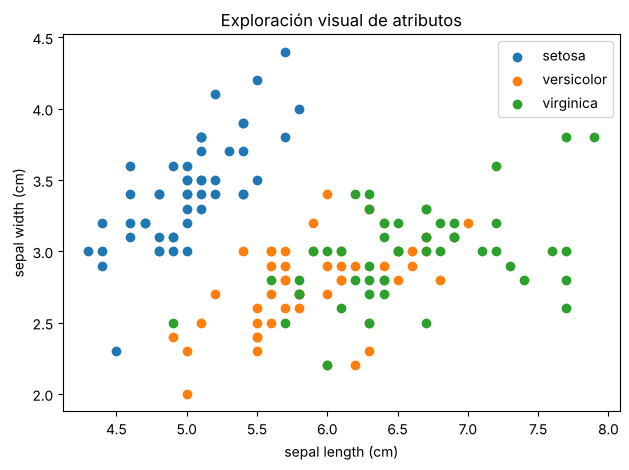

In [7]:
for i, target_name in enumerate(data.target_names):
    plt.scatter(df.loc[df['target'] == i, df.columns[0]],
                df.loc[df['target'] == i, df.columns[1]],
                label=target_name)

plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.title('Exploración visual de atributos')
plt.legend()
plt.tight_layout()
plt.show()

El dataset Iris tiene tres clases objetivo, que corresponden a diferentes variedades de flores. Se modificó el código del scatter plot para incluir una leyenda que muestre la correspondencia entre los colores y nombres de las variedades de Iris usando `data.target_names`.

In [8]:
print(data.target_names)

['setosa' 'versicolor' 'virginica']


El valor `target` en el DataFrame se asigna numéricamente:
*   `0`: setosa
*   `1`: versicolor
*   `2`: virginica

Para que el gráfico sea más claro, se añadió una leyenda que muestre esta correspondencia.

### Resolución del Desafío 1

El gráfico de arriba usa `sepal length` vs `sepal width` (las dos primeras columnas). Para elegir la
mejor pareja graficamos **las 6 combinaciones posibles** de dos atributos.

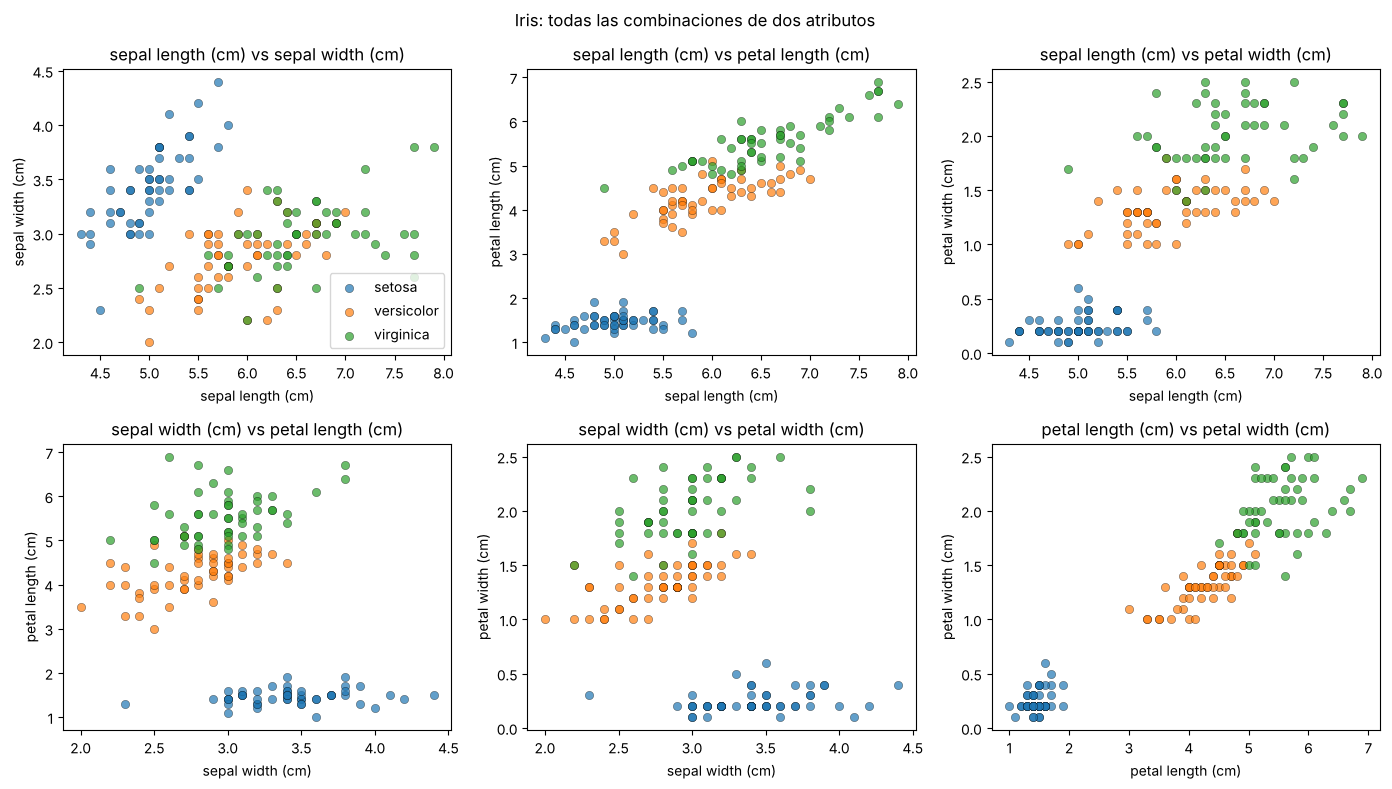

In [9]:
from itertools import combinations

features = data.feature_names
pares = list(combinations(range(4), 2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (a, b) in zip(axes.ravel(), pares):
    for i, target_name in enumerate(data.target_names):
        mask = df['target'] == i
        ax.scatter(df.loc[mask, features[a]], df.loc[mask, features[b]],
                   label=target_name, alpha=0.7, edgecolor='k', linewidth=0.3)
    ax.set_xlabel(features[a])
    ax.set_ylabel(features[b])
    ax.set_title(f'{features[a]} vs {features[b]}')
axes[0, 0].legend()
plt.suptitle('Iris: todas las combinaciones de dos atributos')
plt.tight_layout()
plt.show()

Para no quedarnos solo con la impresión visual, medimos qué tan separables son las clases con cada
pareja: entrenamos una regresión logística **solo con esos dos atributos** y calculamos su accuracy con
validación cruzada de 10 particiones. También medimos, para cada clase, qué tan bien se separa del
resto ("una contra todas").

In [10]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
filas = []
for a, b in pares:
    Xp = X[:, [a, b]]
    fila = {'atributos': f'{features[a]} + {features[b]}',
            'accuracy 3 clases': cross_val_score(LogisticRegression(max_iter=1000), Xp, y, cv=cv10).mean()}
    for i, nombre in enumerate(data.target_names):
        # clase i contra el resto
        fila[f'{nombre} vs resto'] = cross_val_score(LogisticRegression(max_iter=1000),
                                                     Xp, (y == i).astype(int), cv=cv10).mean()
    filas.append(fila)

separabilidad = pd.DataFrame(filas).sort_values('accuracy 3 clases', ascending=False)
separabilidad.round(3)

,atributos,accuracy 3 clases,setosa vs resto,versicolor vs resto,virginica vs resto
1,sepal length (cm) + petal length (cm),0.960,1.0,0.613,0.960
5,petal length (cm) + petal width (cm),0.960,1.0,0.600,0.967
2,sepal length (cm) + petal width (cm),0.953,1.0,0.667,0.960
3,sepal width (cm) + petal length (cm),0.953,1.0,0.707,0.960
4,sepal width (cm) + petal width (cm),0.947,1.0,0.727,0.960
0,sepal length (cm) + sepal width (cm),0.800,1.0,0.707,0.787


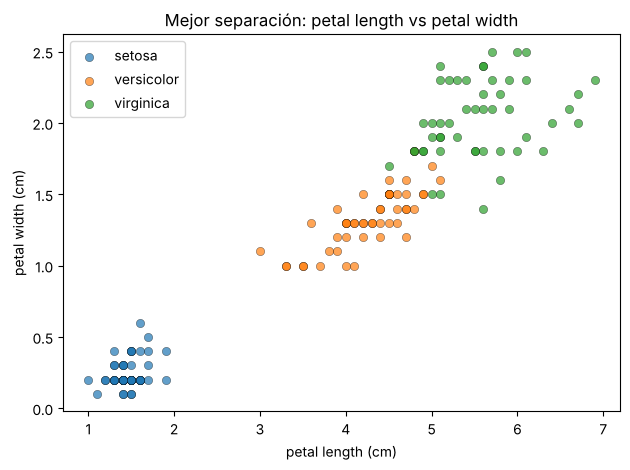

In [11]:
# Mejor pareja: largo y ancho del pétalo
a, b = 2, 3
for i, target_name in enumerate(data.target_names):
    mask = df['target'] == i
    plt.scatter(df.loc[mask, features[a]], df.loc[mask, features[b]],
                label=target_name, alpha=0.7, edgecolor='k', linewidth=0.3)
plt.xlabel(features[a])
plt.ylabel(features[b])
plt.title('Mejor separación: petal length vs petal width')
plt.legend()
plt.tight_layout()
plt.show()

#### Conclusión del Desafío 1

La clase más fácil de separar es **setosa**. En cualquier gráfico que incluya una medida del pétalo,
las setosas forman un grupo aislado de pétalos cortos y angostos (largo < 2 cm, ancho < 0.7 cm), lejos
de las otras dos especies; se puede trazar una recta que las separa sin errores. La tabla lo confirma:
*setosa vs resto* alcanza **100 % con las seis parejas**, incluso con solo las medidas del sépalo.
En cambio *versicolor* y *virginica* se solapan en una zona de valores intermedios, y por eso casi
todos los errores del modelo están entre esas dos clases. *Versicolor* es la más difícil: queda en el
medio, entre setosa y virginica, así que una sola recta no la puede aislar del resto (≈ 60–73 % en
*versicolor vs resto*). Con las medidas del sépalo, versicolor y virginica casi no se distinguen.

**Bonus:** la mejor separación visual fue **`petal length` vs `petal width`**. Ahí las tres clases
quedan ordenadas en franjas casi sin solapamiento, y con solo esos dos atributos el modelo alcanza
≈ 96 % de accuracy, prácticamente lo mismo que con los cuatro (empata con `sepal length` + `petal length`,
pero en ese gráfico las clases se ven más mezcladas). La peor fue `sepal length` vs `sepal width` (≈ 80 %),
justamente la pareja del gráfico original.

## 🧠 Desafío 2 — Vence al Modelo

Tu objetivo es **superar el accuracy obtenido por el modelo base** entrenado en esta actividad.

### Reglas:
- Podés modificar SOLO uno de estos elementos:
  - el tamaño del conjunto de prueba,
  - el modelo (cambiar LogisticRegression por otro simple),
  - o los atributos utilizados (seleccionar solo algunos).

### Pasos:
1. Elegí qué vas a modificar.
2. Entrená nuevamente el modelo.
3. Compará tu accuracy con el original.
4. Explicá por qué creés que tu cambio mejoró o empeoró el rendimiento.

### Bonus:
- Si lográs superar el accuracy por más de 5%, ganás el **Logro: Ajustador de Modelos**.

### Resolución del Desafío 2

**Problema:** el modelo base obtuvo **100 %** en su partición de prueba, y no se puede superar un
100 %. Ese número depende de una partición afortunada de solo 30 flores, así que para comparar de forma
justa evaluamos el modelo base y el modificado con **validación cruzada estratificada repetida** (5
particiones × 10 repeticiones = 50 evaluaciones con distintos datos de prueba). Además mostramos el
resultado en la partición original (`test_size=0.2, random_state=42`).

**Elemento modificado (solo uno): el modelo.** Reemplazamos `LogisticRegression` por
`LinearDiscriminantAnalysis` (LDA), otro clasificador lineal simple. El tamaño del test y los cuatro
atributos quedan igual.

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import RepeatedStratifiedKFold

# 1) Misma partición que el modelo base
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
acc_lda = lda.score(X_test, y_test)
print(f"Partición original -> base (LogReg): {accuracy:.4f} | LDA: {acc_lda:.4f}")

# 2) Comparación robusta: validación cruzada repetida
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
modelos = {
    'Base: LogisticRegression': LogisticRegression(max_iter=1000),
    'Nuevo: LinearDiscriminantAnalysis': LinearDiscriminantAnalysis(),
}
scores = {nombre: cross_val_score(m, X, y, cv=cv_rep) for nombre, m in modelos.items()}

resumen = pd.DataFrame({nombre: {'accuracy media': s.mean(), 'desvío': s.std(),
                                 'mínimo': s.min(), 'máximo': s.max()}
                        for nombre, s in scores.items()}).T
base_cv = scores['Base: LogisticRegression'].mean()
nuevo_cv = scores['Nuevo: LinearDiscriminantAnalysis'].mean()
print(f"\nMejora con validación cruzada: {100 * (nuevo_cv - base_cv):+.2f} puntos porcentuales")
resumen.round(4)

Partición original -> base (LogReg): 1.0000 | LDA: 1.0000



Mejora con validación cruzada: +1.40 puntos porcentuales


,accuracy media,desvío,mínimo,máximo
Base: LogisticRegression,0.9647,0.0301,0.9,1.0
Nuevo: LinearDiscriminantAnalysis,0.9787,0.0229,0.9,1.0


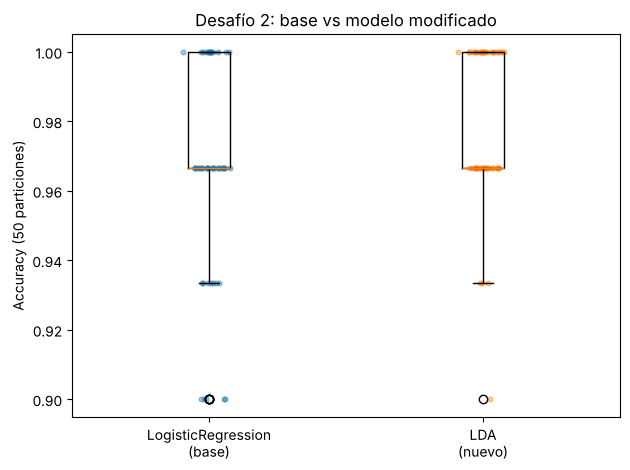

In [13]:
plt.boxplot(list(scores.values()), tick_labels=['LogisticRegression\n(base)', 'LDA\n(nuevo)'])
for k, s in enumerate(scores.values(), start=1):
    plt.scatter(np.random.default_rng(0).normal(k, 0.04, len(s)), s, alpha=0.4, s=12)
plt.ylabel('Accuracy (50 particiones)')
plt.title('Desafío 2: base vs modelo modificado')
plt.tight_layout()
plt.show()

#### Conclusión del Desafío 2

- **Partición original:** LDA también obtiene 100 %, empata con el modelo base. Con esa partición
  ningún cambio puede superar al original, porque ya está en el máximo.
- **Validación cruzada repetida:** LDA obtiene **≈ 97.9 %** frente a **≈ 96.5 %** de la regresión logística,
  es decir **≈ +1.4 puntos** y con menor desvío. Sí **supera al modelo base**.

**¿Por qué mejoró?** LDA supone que cada especie sigue una distribución normal con la misma matriz de
covarianza y traza fronteras lineales a partir de la media y la covarianza de cada clase. En Iris esa
suposición se cumple bastante bien (las medidas de cada especie forman nubes elípticas parecidas), así
que LDA aprovecha la correlación entre atributos (p. ej. largo y ancho del pétalo crecen juntos) para
separar mejor la zona de solapamiento entre *versicolor* y *virginica*, que es donde se cometen los
errores. Además, LDA no aplica regularización, mientras que `LogisticRegression` usa por defecto una
penalización L2 (`C=1.0`) que suaviza un poco las fronteras.

**Bonus (Logro: Ajustador de Modelos):** no se alcanzó una mejora de más de 5 %. El modelo base ya
acierta ≈ 96.5 % en promedio, así que el máximo que se puede ganar es ≈ 3.5 puntos. Superar por más de
5 % solo sería posible partiendo de un modelo base más débil, por ejemplo el que usa solo los atributos
del sépalo (≈ 80 %).